In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [3]:
data = pd.read_csv("C:/Users/ghosh/Downloads/loan_approval_data.csv")
data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


# Preprocessing

In [4]:
data.info()
print(data.shape)
data.describe() # normalize needed
data.isna().sum() # should handle the NA

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [4]:
print(data.duplicated().sum())

0


In [5]:
for cols in data.select_dtypes(include = 'object'):
    print(data[cols].unique())              

['Salaried' 'Self-employed' 'Contract' 'Unemployed' nan]
['Married' 'Single' nan]
['Personal' 'Car' nan 'Business' 'Home' 'Education']
['Urban' 'Semiurban' 'Rural' nan]
['Not Graduate' 'Graduate' nan]
['Female' nan 'Male']
['Private' 'Government' 'Unemployed' nan 'MNC' 'Business']
['No' 'Yes' nan]


# Handling NA

In [6]:
for cols in data.select_dtypes(include = 'number'):
    data[cols] = data[cols].fillna(data[cols].mean())


for cols in data.select_dtypes(include = 'object'):
    data[cols] = data[cols].fillna(data[cols].mode()[0])
data.isna().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA

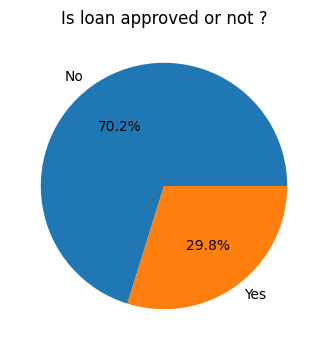

In [7]:
# How balanced our Classes are :
classes_counts = data['Loan_Approved'].value_counts()

plt.figure(figsize=(6,4))
plt.pie(classes_counts, labels = ['No', 'Yes'], autopct="%1.1f%%")
plt.title("Is loan approved or not ?")
plt.show()

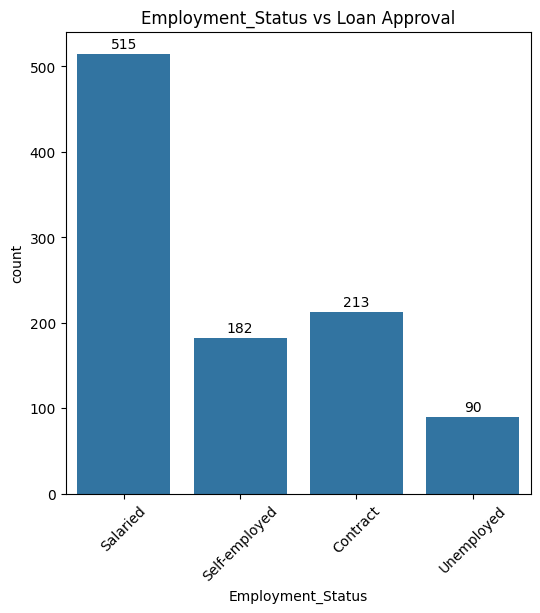

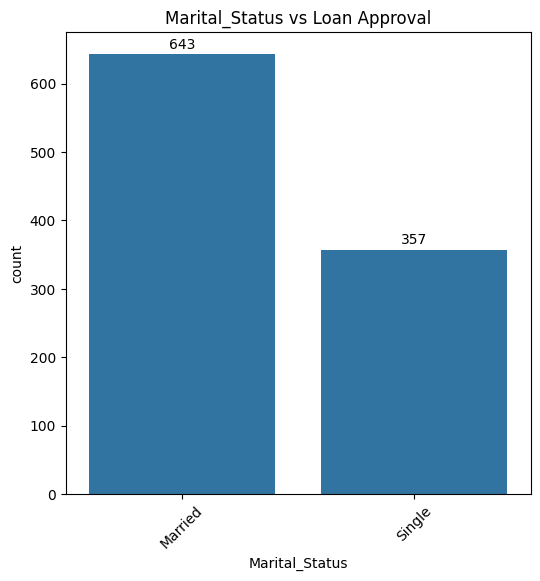

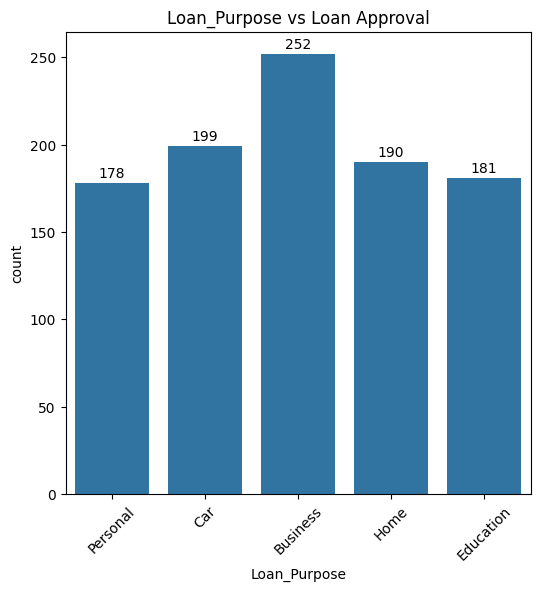

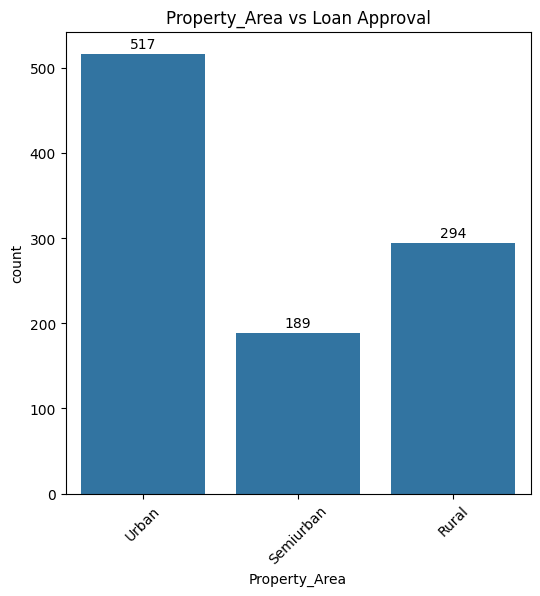

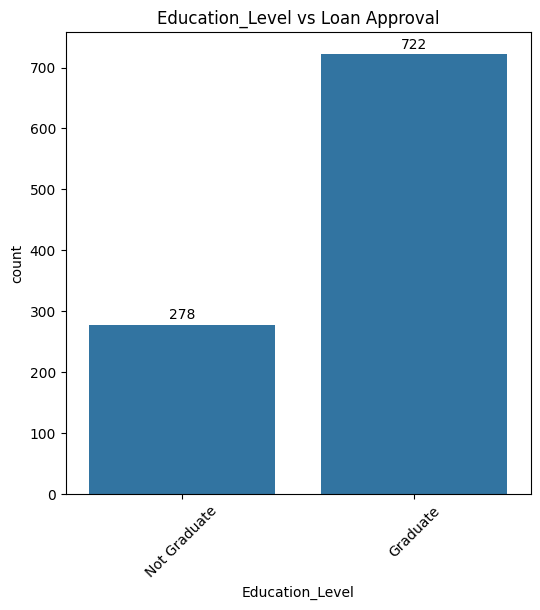

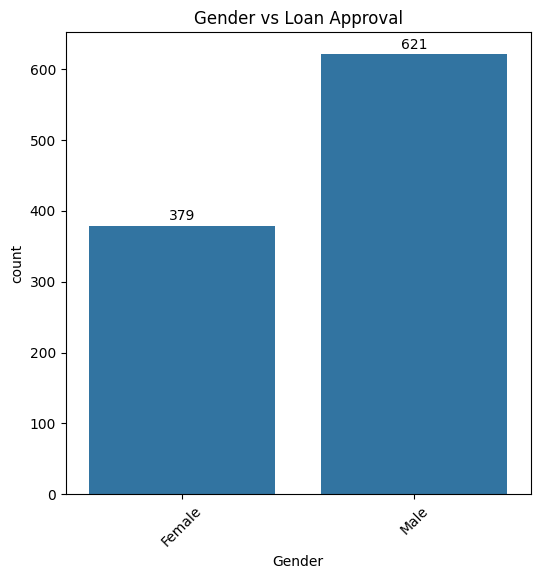

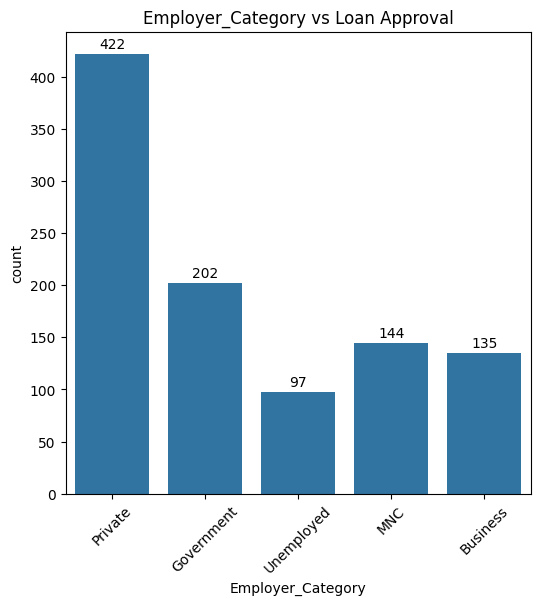

In [8]:
# Analyze categories:
categorical_cols = data.select_dtypes(include='object').columns
for col in categorical_cols:
    if col != 'Loan_Approved':
        plt.figure(figsize=(6, 6))
        ax = sns.countplot(data=data, x=col)
        plt.title(f'{col} vs Loan Approval')
        for container in ax.containers:
            ax.bar_label(container, fmt='%d', padding=2)
        plt.xticks(rotation=45)
        plt.show()

<Axes: xlabel='Applicant_Income', ylabel='Count'>

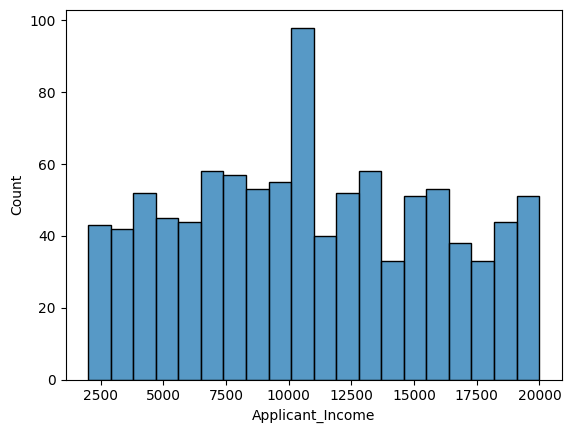

In [9]:
# analyze Applicant_Income

sns.histplot(data = data, x='Applicant_Income', bins = 20)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

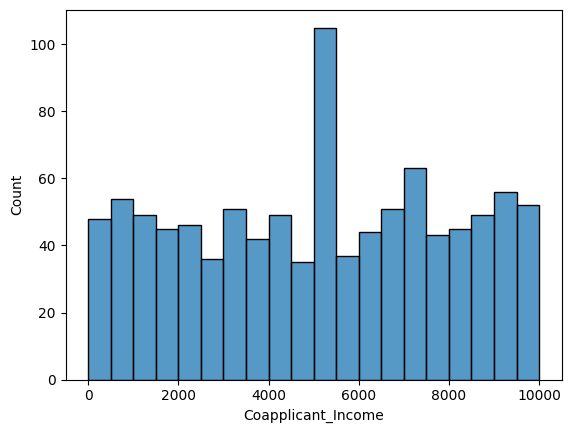

In [10]:
# analyze Coapplicant_Income

sns.histplot(data = data, x='Coapplicant_Income', bins = 20)

In [11]:
# both aplicant and coaplicant income is almost same so we can say if aplicant income is increasing then co coaplicant income is also increasing

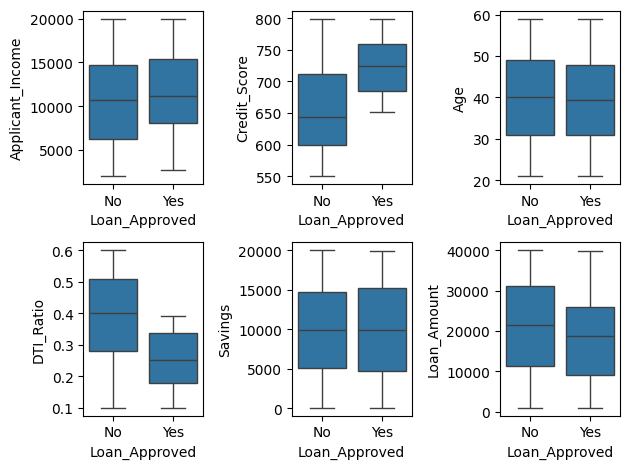

In [12]:
# Finding Outliers
fig, axes = plt.subplots(2, 3)

sns.boxplot(ax = axes[0, 0], data=data, x ='Loan_Approved', y='Applicant_Income')
sns.boxplot(ax = axes[0, 1], data=data, x ='Loan_Approved', y='Credit_Score')
sns.boxplot(ax = axes[1, 0], data=data, x ='Loan_Approved', y='DTI_Ratio')
sns.boxplot(ax = axes[1, 1], data=data, x ='Loan_Approved', y='Savings')
sns.boxplot(ax = axes[0, 2], data=data, x ='Loan_Approved', y='Age')
sns.boxplot(ax = axes[1, 2], data=data, x ='Loan_Approved', y='Loan_Amount')

plt.tight_layout()

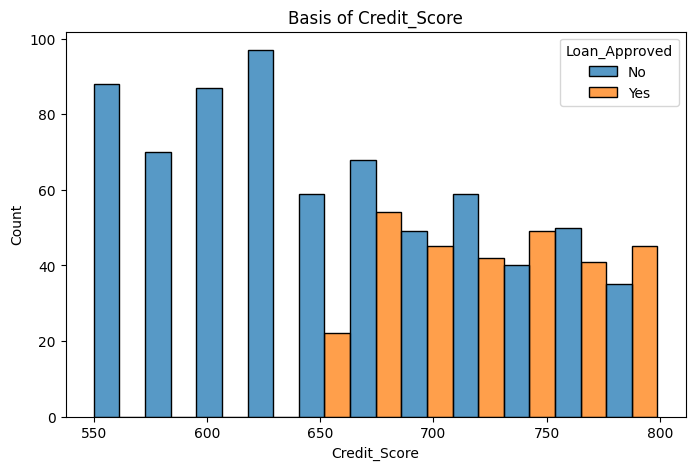

In [13]:
# realtion between applicant_income, credit_score with loan_approved

plt.figure(figsize=(8, 5))
sns.histplot(
    data=data,
    x='Credit_Score',
    hue='Loan_Approved',
    multiple = 'dodge'
)

plt.title('Basis of Credit_Score')
plt.show()

In [14]:
# if the credit score is high the loan_approval chance is also high

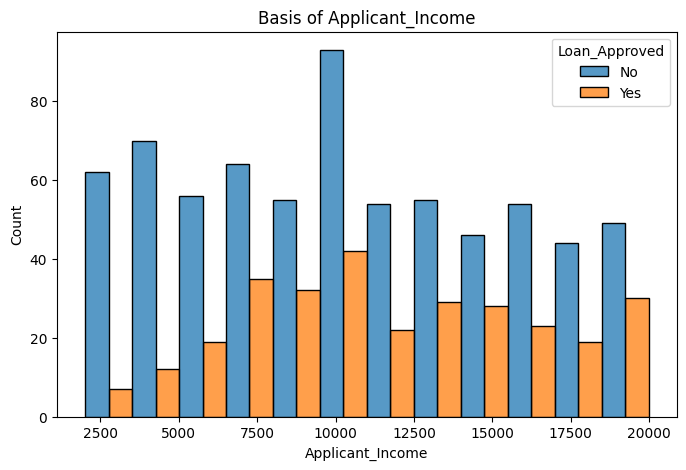

In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=data,
    x='Applicant_Income',
    hue='Loan_Approved',
    multiple = 'dodge'
)

plt.title('Basis of Applicant_Income')
plt.show()

In [16]:
# here also if the applicant income is high then the chances of getting approved is high

In [17]:
data = data.drop('Applicant_ID', axis = 1)

# Encoding

In [18]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder()
data["Education_Level"] = le.fit_transform(data["Education_Level"])
data["Loan_Approved"] = le.fit_transform(data["Loan_Approved"])

In [19]:
OHE_cols = ["Employment_Status", "Marital_Status", "Property_Area", "Loan_Purpose", "Gender", "Employer_Category"]

ohe = OneHotEncoder(drop = 'first', sparse_output = False, handle_unknown='ignore')
encoded = ohe.fit_transform(data[OHE_cols])

ohe.get_feature_names_out(OHE_cols)
encoded_df = pd.DataFrame(encoded, columns = ohe.get_feature_names_out(OHE_cols), index = data.index)

data = pd.concat([data.drop(columns = OHE_cols), encoded_df], axis = 1)

In [20]:
data.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Property_Area_Urban,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


# Co Relation Heat map

In [21]:
num_cols = data.select_dtypes(include = 'number')
corr_matrix = num_cols.corr()
num_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

<Axes: >

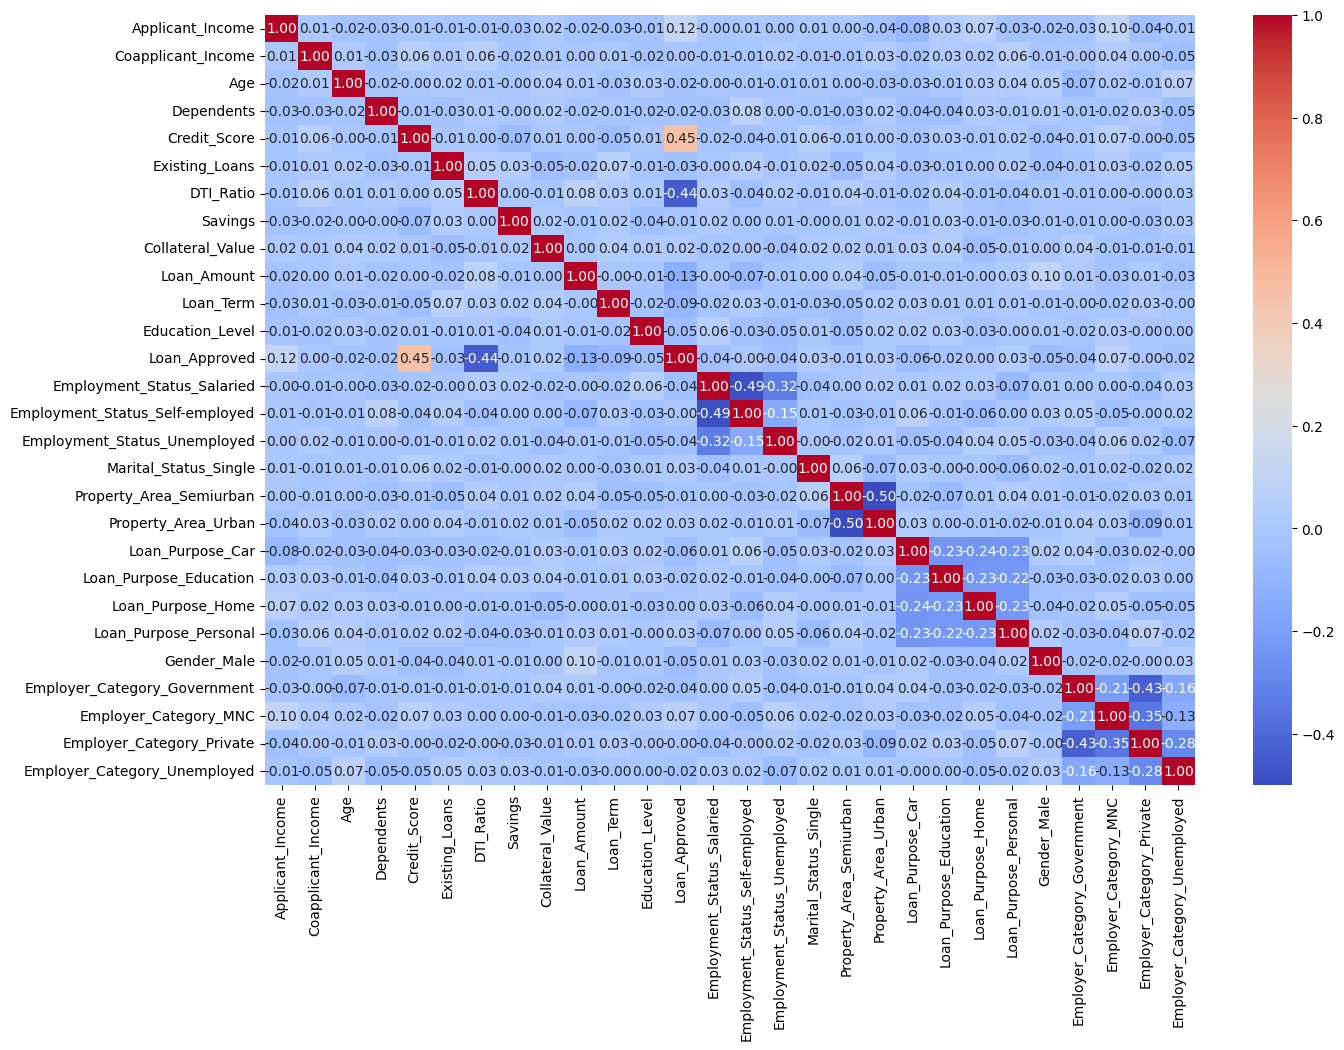

In [22]:
plt.figure(figsize=(15, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

# Train Test Split + Feature Scaling

In [23]:
X = data.drop("Loan_Approved", axis = 1)
Y = data["Loan_Approved"]

In [24]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train and Evaluate Model

In [26]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train_scaled, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [27]:
y_pred = log_model.predict(X_test_scaled)

print("Logistic Regression")
print("accuracy: ", accuracy_score(Y_test, y_pred))
print("Precision: ", precision_score(Y_test, y_pred))
print("recall: ", recall_score(Y_test, y_pred))
print("F1 score: ", f1_score(Y_test, y_pred))
print("CM: ", confusion_matrix(Y_test, y_pred))

Logistic Regression
accuracy:  0.865
Precision:  0.7833333333333333
recall:  0.7704918032786885
F1 score:  0.7768595041322314
CM:  [[126  13]
 [ 14  47]]


In [28]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, Y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [29]:
y_pred = knn_model.predict(X_test_scaled)

print("KNN")
print("accuracy: ", accuracy_score(Y_test, y_pred))
print("Precision: ", precision_score(Y_test, y_pred))
print("recall: ", recall_score(Y_test, y_pred))
print("F1 score: ", f1_score(Y_test, y_pred))
print("CM: ", confusion_matrix(Y_test, y_pred))

KNN
accuracy:  0.76
Precision:  0.6274509803921569
recall:  0.5245901639344263
F1 score:  0.5714285714285714
CM:  [[120  19]
 [ 29  32]]


In [30]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB

NB_model = GaussianNB()
NB_model.fit(X_train_scaled, Y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [31]:
y_pred = NB_model.predict(X_test_scaled)

print("Naive Bayes")
print("accuracy: ", accuracy_score(Y_test, y_pred))
print("Precision: ", precision_score(Y_test, y_pred))
print("recall: ", recall_score(Y_test, y_pred))
print("F1 score: ", f1_score(Y_test, y_pred))
print("CM: ", confusion_matrix(Y_test, y_pred))

Naive Bayes
accuracy:  0.865
Precision:  0.8035714285714286
recall:  0.7377049180327869
F1 score:  0.7692307692307693
CM:  [[128  11]
 [ 16  45]]


# Here In this case Best Model on the basis of precision is => "Naive Bayes"

# Feature Engineering

In [32]:
data['DTI_Ratio_sq']=data['DTI_Ratio']**2
data['Credit_Score_sq']=data['Credit_Score']**2

#data["Applicant_Income_log"] = np.log1p(data["Applicant_Income"]) # this is for skewd value if we have something

X = data.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio", "Applicant_Income"])
Y = data["Loan_Approved"]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [33]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
# Logistic regression
log_model = LogisticRegression()
log_model.fit(X_train_scaled, Y_train)

y_pred = log_model.predict(X_test_scaled)

print("Logistic Regression")
print("accuracy: ", accuracy_score(Y_test, y_pred))
print("Precision: ", precision_score(Y_test, y_pred))
print("recall: ", recall_score(Y_test, y_pred))
print("F1 score: ", f1_score(Y_test, y_pred))
print("CM: ", confusion_matrix(Y_test, y_pred))

Logistic Regression
accuracy:  0.855
Precision:  0.75
recall:  0.7868852459016393
F1 score:  0.768
CM:  [[123  16]
 [ 13  48]]


In [35]:
# KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, Y_train)

y_pred = knn_model.predict(X_test_scaled)

print("KNN")
print("accuracy: ", accuracy_score(Y_test, y_pred))
print("Precision: ", precision_score(Y_test, y_pred))
print("recall: ", recall_score(Y_test, y_pred))
print("F1 score: ", f1_score(Y_test, y_pred))
print("CM: ", confusion_matrix(Y_test, y_pred))

KNN
accuracy:  0.755
Precision:  0.625
recall:  0.4918032786885246
F1 score:  0.5504587155963303
CM:  [[121  18]
 [ 31  30]]


In [36]:
#Naive Bayes
NB_model = GaussianNB()
NB_model.fit(X_train_scaled, Y_train)

y_pred = NB_model.predict(X_test_scaled)

print("Naive Bayes")
print("accuracy: ", accuracy_score(Y_test, y_pred))
print("Precision: ", precision_score(Y_test, y_pred))
print("recall: ", recall_score(Y_test, y_pred))
print("F1 score: ", f1_score(Y_test, y_pred))
print("CM: ", confusion_matrix(Y_test, y_pred))

Naive Bayes
accuracy:  0.855
Precision:  0.7758620689655172
recall:  0.7377049180327869
F1 score:  0.7563025210084033
CM:  [[126  13]
 [ 16  45]]


# Here we can take the call that in All the cases our "Naive Bayes" is working fine after feature engineering also